# 03 · Embeddings to a held-out classification map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute. Download: 0 bytes. Source: historical Wuhan
567 nominal-500 m grid cells, AEF **2021** pooled embeddings and ESA WorldCover
**2021 v200** grouped dominant labels (both CC-BY-4.0; see bundled provenance).
This is a software teaching example, **not reproduction of the current global
paper benchmark**. It does not add any model to the frozen 20-system study.

The original random stratified split is retained for provenance but not used.
East columns >=25 train; west columns <=22 test; columns 23–24 form an unused
two-column spatial buffer. Five rare cropland tiles remain visible but are
excluded from this explicitly three-class probe. No parameter selection or
test-label tuning: StandardScaler + LogisticRegression(C=1, seed=42).

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")
import json
from earth_embedding.demo import classify_demo, plot_classification

CPU demo; outputs are saved in ./outputs


In [2]:
wuhan = load_demo("wuhan")
result = classify_demo(wuhan)
display(__import__("pandas").crosstab(result["samples"].demo_split, result["samples"].class_name))
print(json.dumps(result["metrics"], indent=2))

class_name,built,cropland,vegetation,water
demo_split,,,,
buffer,26,0,8,8
excluded_rare_class,0,5,0,0
test,95,0,40,75
train,120,0,152,38


{
  "scope": "Historical Wuhan software demonstration, three classes; not global benchmark reproduction",
  "seed": 42,
  "model": "AEF 2021 historical mean-pooled features",
  "total": 567,
  "split_counts": {
    "train": 310,
    "test": 210,
    "buffer": 42,
    "excluded_rare_class": 5
  },
  "class_counts": {
    "buffer": {
      "built": 26,
      "cropland": 0,
      "vegetation": 8,
      "water": 8
    },
    "excluded_rare_class": {
      "built": 0,
      "cropland": 5,
      "vegetation": 0,
      "water": 0
    },
    "test": {
      "built": 95,
      "cropland": 0,
      "vegetation": 40,
      "water": 75
    },
    "train": {
      "built": 120,
      "cropland": 0,
      "vegetation": 152,
      "water": 38
    }
  },
  "split": "East col >=25 train; west col <=22 test; cols 23,24 buffer; exclude 5 cropland tiles",
  "classes": [
    "built",
    "vegetation",
    "water"
  ],
  "oa": 0.9380952380952381,
  "macro_f1": 0.9192094067375609,
  "balanced_accuracy": 0.90

In [3]:
train = result["samples"].demo_split.eq("train").to_numpy()
np.testing.assert_allclose(result["estimator"].named_steps["standardscaler"].mean_, wuhan.features[train].mean(axis=0, dtype=np.float64))
assert result["samples"].loc[~result["samples"].demo_split.eq("test"), "prediction"].isna().all()
print("Scaler fitted on train only; predictions and metrics restricted to held-out west.")

Scaler fitted on train only; predictions and metrics restricted to held-out west.


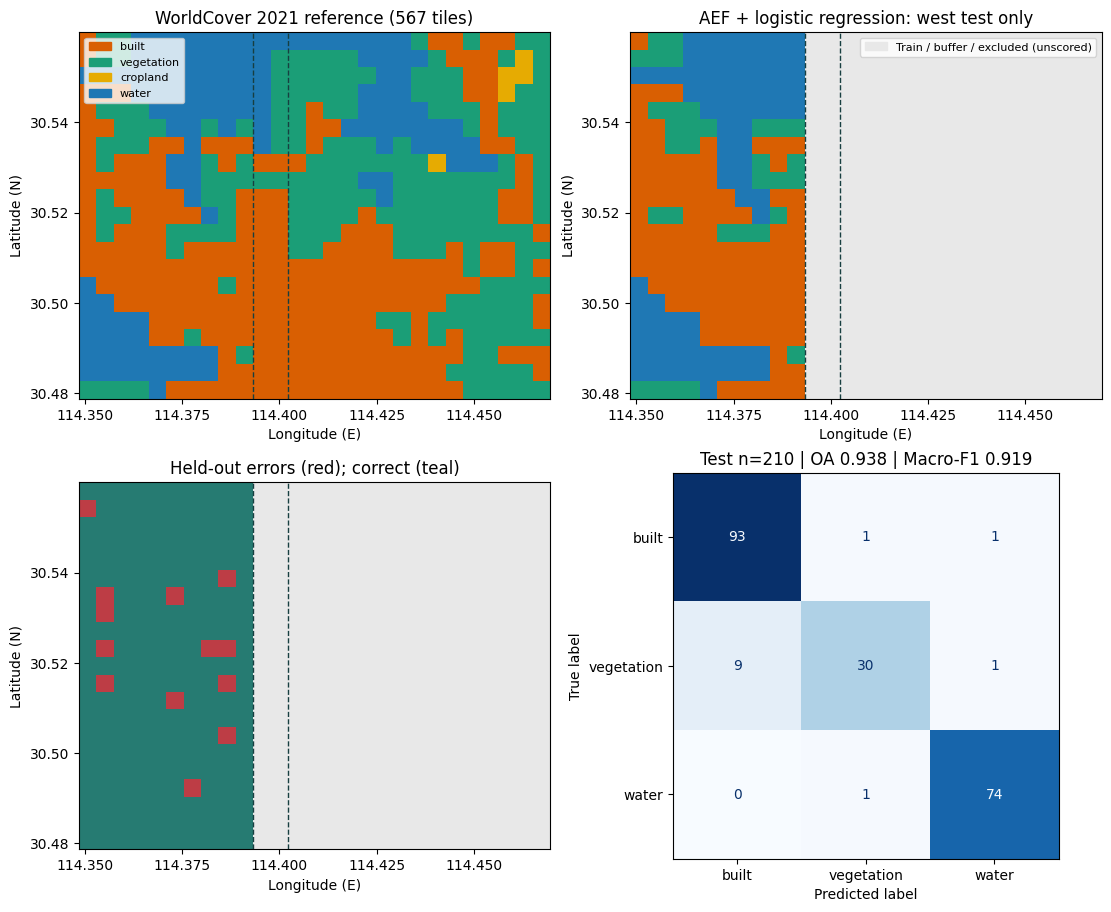

In [4]:
fig = plot_classification(result)
fig.savefig(out / "wuhan-classification.png", dpi=160)
result["samples"].to_csv(out / "predictions.csv", index=False)
(out / "metrics.json").write_text(json.dumps(result["metrics"], indent=2))
plt.show()

Gray areas have no held-out prediction. Red errors and confusion-matrix
rows compare predictions to WorldCover reference labels, not field-survey truth.
OA is overall accuracy; Macro-F1 gives each of the three classes equal weight;
Balanced Accuracy is mean per-class recall. One small holdout has no uncertainty
estimate or global generalization claim. Same-year input and reference products
may share satellite signals; the buffer reduces immediate adjacency leakage,
but does not remove all spatial autocorrelation.